In [6]:
import networkx as nx
import numpy as np
import seaborn as sns
import sympy as sp
from pprint import pprint

from auxin_signalling_models.AuxinSignallingPathway import \
    AuxinSignallingPathway as asp_class


In [9]:
# Generate a simple model with 1 ARF and 2 Aux/Iaas
asp_model = asp_class(nARFs=1, nIAAs=2)

# Output default initial conditions and parameters
print('default initial conditions:')
pprint(asp_model.get_default_initial_conditions())

print('\n\ndefault parameter values:')
pprint(asp_model.get_default_parameters())

default_parameters = asp_model.get_default_parameters()
default_initial_conditions = asp_model.get_default_initial_conditions()

odes, free_vars, param_dict, constraints = asp_model.generate_ode_system()
ode_dict = {var: ode for var, ode in zip(default_initial_conditions, odes)}
print('\n\n')
pprint(ode_dict)

default initial conditions:
{'ARF_1': 1.0,
 'D__ARF_1__ARF_1': 0.1,
 'D__ARF_1__iaa_1': 0.1,
 'D__ARF_1__iaa_2': 0.1,
 'D__iaa_1__iaa_1': 0.1,
 'D__iaa_1__iaa_2': 0.1,
 'D__iaa_2__iaa_2': 0.1,
 'G': 1.0,
 'G__ARF_1': 0.0,
 'G__ARF_1__ARF_1': 0.0,
 'G__ARF_1__iaa_1': 0.0,
 'G__ARF_1__iaa_2': 0.0,
 'R__iaa_1': 0.0,
 'R__iaa_2': 0.0,
 'iaa_1': 0.1,
 'iaa_2': 0.1}


default parameter values:
{'d__D__ARF_1__ARF_1': 0.1,
 'd__D__ARF_1__iaa_1': 0.1,
 'd__D__ARF_1__iaa_2': 0.1,
 'd__D__iaa_1__iaa_1': 0.1,
 'd__D__iaa_1__iaa_2': 0.1,
 'd__D__iaa_2__iaa_2': 0.1,
 'd__G__ARF_1': 1.0,
 'd__G__ARF_1__ARF_1': 1.0,
 'd__G__ARF_1__iaa_1': 1.0,
 'd__G__ARF_1__iaa_2': 1.0,
 'd__R': 0.01,
 'd__arf__all': 1.0,
 'd__iaa_1__x': 0.1,
 'd__iaa_2__x': 0.1,
 'd__iaa__all': 1.0,
 'k__D__ARF_1__ARF_1': 0.001,
 'k__D__ARF_1__iaa_1': 0.001,
 'k__D__ARF_1__iaa_2': 0.001,
 'k__D__iaa_1__iaa_1': 0.001,
 'k__D__iaa_1__iaa_2': 0.001,
 'k__D__iaa_2__iaa_2': 0.001,
 'k__G__ARF_1': 1.0,
 'k__G__ARF_1__ARF_1': 1.0,
 'k__G__

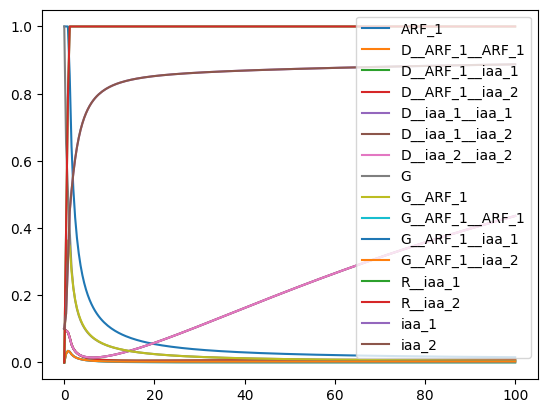

In [10]:
solver = asp_model.make_forward_solver()

ts = np.linspace(0, 100, 250)

aux_level = 1.0
default_output, success = solver(ts, default_parameters,
                            default_initial_conditions,
                            1.0)

import matplotlib.pyplot as plt
plt.plot(ts, default_output / default_output.max(axis=1)[:, None],
         label=list(default_initial_conditions))
plt.legend()
plt.show()

{'d__D__ARF_1__iaa_1': (0.05, 0.1), 'd__G__ARF_1': (0.01, 1.0), 'd__G__ARF_1__ARF_1': (0.01, 1.0), 'd__G__ARF_1__iaa_1': (0.01, 1.0), 'd__G__ARF_1__iaa_2': (0.01, 1.0), 'd__R': (0.004166666666666667, 0.01), 'k__D__ARF_1__ARF_1': (0.25, 0.001), 'k__D__ARF_1__iaa_1': (0.75, 0.001), 'k__D__ARF_1__iaa_2': (0.25, 0.001), 'k__D__iaa_1__iaa_1': (0.25, 0.001), 'k__D__iaa_1__iaa_2': (0.25, 0.001), 'k__D__iaa_2__iaa_2': (0.25, 0.001), 'k__G__ARF_1': (0.1, 1.0), 'k__G__ARF_1__ARF_1': (0.1, 1.0), 'k__G__ARF_1__iaa_1': (0.1, 1.0), 'k__G__ARF_1__iaa_2': (0.1, 1.0), 'k__G__R__iaa_1': (0.01, 1.0), 'k__G__R__iaa_2': (0.01, 1.0), 'k__R__iaa_1__iaa_1': (0.01, 1.0), 'k__R__iaa_2__iaa_2': (0.01, 1.0), 'd__iaa_1__x': (1.0, 0.1), 'd__iaa_2__x': (1.0, 0.1)}


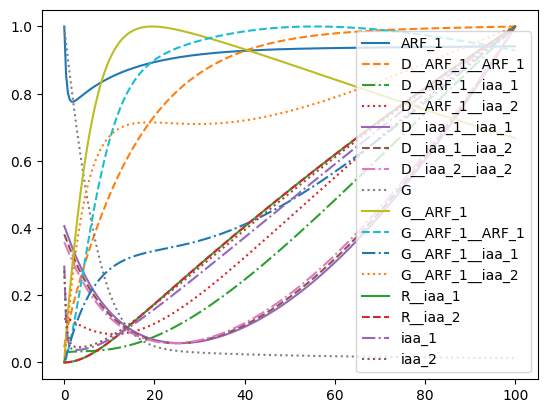

In [25]:
custom_parameters = \
{'d__iaa__all': 1.0,
 'd__D__ARF_1__ARF_1': 0.1,
 'd__D__ARF_1__iaa_1': 0.05,
 'd__D__ARF_1__iaa_2': 0.1,
 'd__D__iaa_1__iaa_1': 0.1,
 'd__D__iaa_1__iaa_2': 0.1,
 'd__D__iaa_2__iaa_2': 0.1,
 'd__G__ARF_1': 0.01,
 'd__G__ARF_1__ARF_1': 0.01,
 'd__G__ARF_1__iaa_1': 0.01,
 'd__G__ARF_1__iaa_2': 0.01,
 'd__R': 0.004166666666666667,
 'k__D__ARF_1__ARF_1': 0.25,
 'k__D__ARF_1__iaa_1': 0.75,
 'k__D__ARF_1__iaa_2': 0.25,
 'k__D__iaa_1__iaa_1': 0.25,
 'k__D__iaa_1__iaa_2': 0.25,
 'k__D__iaa_2__iaa_2': 0.25,
 'k__G__ARF_1': 0.1,
 'k__G__ARF_1__ARF_1': 0.1,
 'k__G__ARF_1__ARF_1__R__iaa_1': 1.0,
 'k__G__ARF_1__ARF_1__R__iaa_2': 1.0,
 'k__G__ARF_1__R__iaa_1': 1.0,
 'k__G__ARF_1__R__iaa_2': 1.0,
 'k__G__ARF_1__iaa_1': 0.1,
 'k__G__ARF_1__iaa_1__R__iaa_1': 1.0,
 'k__G__ARF_1__iaa_1__R__iaa_2': 1.0,
 'k__G__ARF_1__iaa_2': 0.1,
 'k__G__ARF_1__iaa_2__R__iaa_1': 1.0,
 'k__G__ARF_1__iaa_2__R__iaa_2': 1.0,
 'k__G__R__iaa_1': 0.01,
 'k__G__R__iaa_2': 0.01,
 'k__R__iaa_1__iaa_1': 0.01,
 'k__R__iaa_2__iaa_2': 0.01,
 'd__arf__all': 1.0,
 'd__iaa_1__x': 1.0,
 'd__iaa_2__x': 1.0,
 'k__arf__all': 1.0
}

ts = np.linspace(0, 100, 250)

diff = { k : (custom_parameters[k], default_parameters[k]) for k in list(custom_parameters.keys()) + list(default_parameters.keys())
        if custom_parameters[k] != default_parameters[k]
       }

print(diff)

output, success = solver(ts, custom_parameters,
                            default_initial_conditions,
                            1.0)
import matplotlib.pyplot as plt
from itertools import cycle
lines = ["-","--","-.",":"]
linecycler = cycle(lines)

for i in range(output.shape[1]):
    plt.plot(ts, output[:, i] / output[:, i].max(), label=list(default_initial_conditions)[i],
            linestyle=next(linecycler))
plt.legend()
plt.show()

R_iaa1_index = [i for i, k in enumerate(ode_dict) if k=='R__iaa_1'][0]
R_iaa2_index = [i for i, k in enumerate(ode_dict) if k=='R__iaa_2'][0]

assert np.all(output[:, R_iaa1_index] - output[:, R_iaa2_index] == 0)